In [1]:
from collections import Counter

import numpy as np
from regina.engine import Triangulation3
from tqdm import tqdm

from pachner_traversal.classical_search.mcmc import iterate

In [12]:
seed_dehydration = "dadbcccdxff"
seed = Triangulation3.rehydrate(seed_dehydration).isoSig()

char_to_size = dict(zip(list('abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'), range(52)))

count_15 = {}

for gamma_ in np.linspace(1/7, 1/5, 10):
    iso = seed
    sizes = Counter([char_to_size[iso[0]]])

    for i in tqdm(range(10_000), miniters=1_000):
        iso = iterate(iso, gamma_, 1)
        sizes.update([char_to_size[iso[0]]])

    count_15[gamma_] = sizes[15]

100%|██████████| 10000/10000 [00:06<00:00, 1486.36it/s]


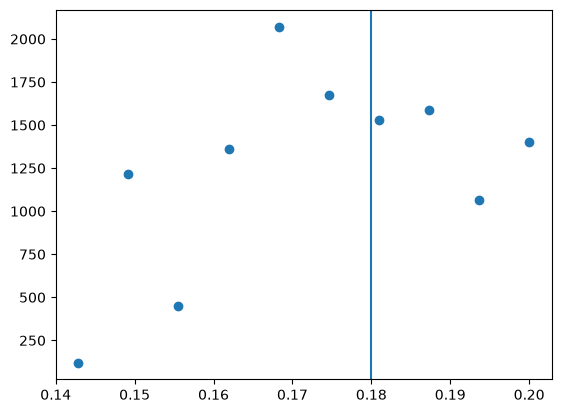

In [13]:
import matplotlib.pyplot as plt

plt.scatter(list(count_15.keys()), list(count_15.values()))
plt.axvline(0.18)
plt.show()

In [23]:
all_sigs = []

for c in 'abcdefg':
    with open(f"/home/dbruwel/main/honours/pachner_graph_triangulations/data/input_data/dehydration/score_data/raw_data/s3{c}9.txt") as f:
        sigs = f.readlines()
        sigs = [s.strip() for s in sigs]
        sigs = sigs[5_000:]
        sigs = [s for s in sigs if s.startswith("j")]
        all_sigs.extend(sigs)

In [24]:
len(all_sigs)

148937

In [25]:
with open(
    "/home/dbruwel/main/honours/pachner_graph_triangulations/data/input_data/dehydration/score_data/spheres9/uniform.txt",
    "w",
) as f:
    f.write("\n".join(all_sigs[:100_000]))